# Recorded n-back session
Demo of the `record` package using the simulated EEG driver.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from hotb_2026.brainaccess_connection import MONTAGE, SimulatedDriver
from hotb_2026.record import run_session, run_experiment


## Single session

In [2]:
out_dir = Path('data')
driver = SimulatedDriver(MONTAGE)
session_dir = run_session(
    subject_id='demo',
    session_idx=1,
    driver=driver,
    montage=MONTAGE,
    out_dir=out_dir,
    seed=42,
    fullscreen=False,
    min_duration=5,
    max_duration=8,
    n_blocks=3,
)
print(session_dir)


1.2741 	WARNING 	Monitor specification not found. Creating a temporary one...
data/session_1


In [3]:
import json
meta = json.loads((session_dir / 'meta.json').read_text())
print(meta)
signal = np.load(session_dir / 'signal.npy')
time = np.load(session_dir / 'time.npy')
print('signal', signal.shape, 'time', time.shape)
print((session_dir / 'state_changes.csv').read_text())


{'session_id': 'demo_1', 'subject_id': 'demo', 'electrodes': ['F3', 'F4', 'C3', 'C4', 'P3', 'P4', 'O1', 'O2'], 'sfreq': 250.0, 'n_channels': 8, 'session_idx': 1, 'n_samples': 3990, 'created_at': '2026-11-15T00:52:28.285667+00:00'}
signal (3990, 8) time (3990,)
time,label
2.08,3back
13.04,rest
22.68,rest



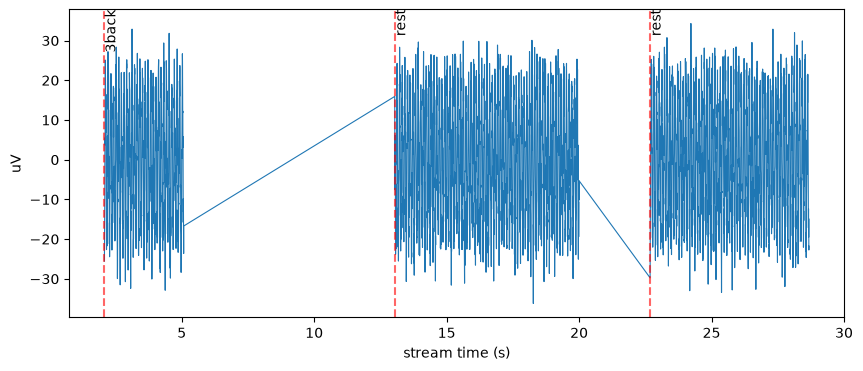

In [4]:
changes = np.loadtxt(session_dir / 'state_changes.csv', delimiter=',', skiprows=1, dtype=str)
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(time, signal[:,0], lw=0.8)
if changes.ndim == 1:
    changes = changes.reshape(1,-1)
for row in changes:
    t = float(row[0]); label = row[1]
    ax.axvline(t, color='r', linestyle='--', alpha=0.6)
    ax.text(t, ax.get_ylim()[1], label, rotation=90, va='top')
ax.set_xlabel('stream time (s)')
ax.set_ylabel('uV')
plt.show()


## Multiple sessions

In [5]:
driver = SimulatedDriver(MONTAGE)
sessions = run_experiment(
    subject_id='demo',
    n_sessions=2,
    driver=driver,
    montage=MONTAGE,
    out_dir=out_dir,
    seed=7,
    fullscreen=False,
    min_duration=5,
    max_duration=8,
    n_blocks=2,
)
print(sessions)


69.2574 	WARNING 	Monitor specification not found. Creating a temporary one...


KeyboardInterrupt: 

## CLI equivalent
`uv run hotb-record --simulate --subject demo --sessions 1 --seed 42`